Outline
1. Excel exercise of simple model - interactive formula
2. Build the exercise in GreenLight



### Imports - can ignore

In [92]:
### Imports needed for running the code and other general setup
import warnings
warnings.filterwarnings("ignore")

import os

from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd
import greenlight

## Tunnel model in GreenLight

### Defining the model

In [2]:
# Define model variables
tunnel_model = {
    "tau": {
        "description": "Transmissivity (hemispherical) of the cover for sun radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.2",
        "definition": "0.7",
        "type": "const"
    },
    "iSun": {
        "description": "Solar radiation",
        "unit": "W/m2",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "700",
        "type": "input"
    },
    "fTunnelSky": {
        "description": "View factor between tunnel and sky",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5",
        "definition": "0.5",
        "type": "const"
    },
    "epsCover": {
        "description": "Emissivity of the cover, including effect of screen(s)",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.3",
        "definition": "1",
        "type": "const"
    },
    "alphaR": {
        "description": "Apparent transfer coefficient for thermal radiation",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.6",
        "definition": "6",
        "type": "const"
    },
    "tSky": {
        "description": "Apparent temperature of the sky (depends, among other things, on cloudiness)",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "0",
        "type": "input"
    },
    "tOut": {
        "description": "Temperature of the air outside the greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "30",
        "type": "input"
    },
    "tSoil": {
        "description": "Temperature of the soil surface",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9",
        "definition": "35",
        "type": "input"
    },
    "fTunnelSoil": {
        "description": "View factor between tunnel and soil",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.5",
        "definition": "0.5",
        "type": "const"
    },
    "epsSoil": {
        "description": "Emissivity of the soil, including possible effect of mulch",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.3",
        "definition": "1",
        "type": "const"
    },
    "aCoverOverSoil": {
        "description": "Surface area of cover per unit surface area of soil",
        "unit": "-",
        "reference": "Stanghellini et al. (2024), Eq. 3.7. This variable is used to represent aCover divided by aSoil",
        "definition": "1.2",
        "type": "const"
    },
    "alphaCover": {
        "description": "Heat transfer coefficient of the cover material (including possible screens)",
        "unit": "W/m2/K",
        "reference": "Stanghellini et al. (2024), Eq. 3.7",
        "definition": "6",
        "type": "const"
    },
    "alphaSoil": {
        "description": "Heat transfer coefficient of the soil (including possible mulches)",
        "unit": "W/m2/K",
        "reference": "Stanghellini et al. (2024), Eq. 3.68",
        "definition": "5",
        "type": "const"
    }
}

In [73]:
tunnel_model["tTunnel"] = {
        "description": "Temperature of the unventilated greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9 (rearranged to isolate tTunnel)",
        "type": "aux",
        "definition": "(" \
        "tau * iSun " \
        "+ fTunnelSky * epsCover * alphaR * tSky " \
        "+ aCoverOverSoil * alphaCover * tOut " \
        "+ tSoil * (fTunnelSoil * epsSoil * alphaR + alphaSoil)" \
    ") / ( " \
        "fTunnelSky * epsCover * alphaR " \
        "+ aCoverOverSoil * alphaCover " \
        "+ fTunnelSoil * epsSoil * alphaR " \
        "+ alphaSoil " \
    ")"
    }

In [4]:
mdl = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=tunnel_model, 
    output_path=os.path.join("output", "output.csv")
)

In [5]:
mdl.run()



Simulation started at time (ISO format): 2026-07-30T12:04:36.866173
Running: 0.00%

Simulation complete at time (ISO format): 2026-07-30T12:04:36.877255
Simulated 1.0 days
Elapsed time: 0.011081457138061523 seconds
Output saved to file output\output.csv
Model structure log saved to output\output_model_struct_log.json
Simulation log saved to output\output_simulation_log.txt


In [6]:
"""Load simulation result"""
output_df = pd.read_csv(os.path.join("output", "output.csv"), header=[0,1,2], low_memory=False)

display(
    output_df.style
      .format("{:.2f}")
      .set_properties(**{"text-align": "left"})
      .set_table_styles([
          {"selector": "th", "props": [("text-align", "left")]}
      ])
)

,Time,iSun,tSky,tOut,tSoil,tTunnel
,no_description,Solar radiation,"Apparent temperature of the sky (depends, among other things, on cloudiness)",Temperature of the air outside the greenhouse,Temperature of the soil surface,Temperature of the unventilated greenhouse
,no_unit_defined,W/m2,°C,°C,°C,°C
0,0.00,700.00,0.00,30.00,35.00,54.18
1,3600.00,700.00,0.00,30.00,35.00,54.18
2,7200.00,700.00,0.00,30.00,35.00,54.18
3,10800.00,700.00,0.00,30.00,35.00,54.18
4,14400.00,700.00,0.00,30.00,35.00,54.18
5,18000.00,700.00,0.00,30.00,35.00,54.18
6,21600.00,700.00,0.00,30.00,35.00,54.18
7,25200.00,700.00,0.00,30.00,35.00,54.18


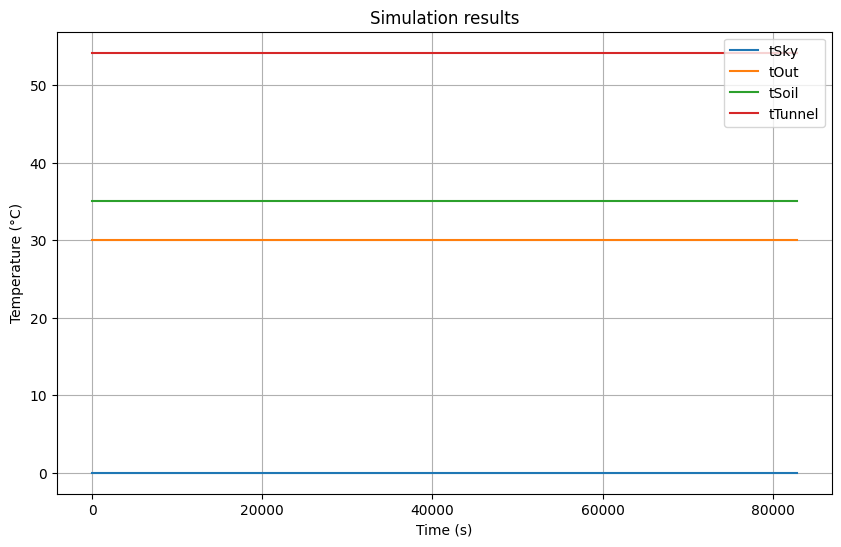

In [7]:
"""Make graphs"""
variable_names = output_df.columns.get_level_values(0)
descriptions = output_df.columns.get_level_values(1)
units = output_df.columns.get_level_values(2)

# Create dictionaries for descriptions and units
descriptions_dict = dict(zip(variable_names, descriptions))
units_dict = dict(zip(variable_names, units))

"""Present results in a graph graphs"""
# Choose variables out of output_df.columns
# For a description of a variable var, see descriptions_dict[var]. For the unit, see units_dict[var]
chosen_vars = ["tSky", "tOut", "tSoil", "tTunnel"]

plt.figure(figsize=(10, 6))

for var in chosen_vars:
    plt.plot(output_df["Time"], output_df[var], label=var)

plt.xlabel("Time (s)")
plt.ylabel("Temperature (°C)")
plt.title("Simulation results")
plt.legend()
plt.grid(True)
plt.show()

In [125]:
# New model
options = {
    "options": {
        "t_start": str(15 * 24 * 60 * 60),
        "t_end": str(25 * 24 * 60 * 60),
        "output_step": "300",
        "t_eval": "300"
    }
}

tunnel_model["Time"] = {
      "unit" : "s",
      "type" : "time",
      "description" : "Time since start of data"
   }

tunnel_model["dummy"] = {
        "description": "Dummy variable",
        "unit": "-",
        "reference": "Used to get the model going",
        "type": "state",
        "definition": "0",
        "init": "0"
    }

tunnel_model["tTunnel"] = {
        "description": "Temperature of the unventilated greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9 (rearranged to isolate tTunnel)",
        "type": "aux",
        "definition": "(" \
        "tau * iSun " \
        "+ fTunnelSky * epsCover * alphaR * tSky " \
        "+ aCoverOverSoil * alphaCover * tOut " \
        "+ tSoil * (fTunnelSoil * epsSoil * alphaR + alphaSoil)" \
    ") / ( " \
        "fTunnelSky * epsCover * alphaR " \
        "+ aCoverOverSoil * alphaCover " \
        "+ fTunnelSoil * epsSoil * alphaR " \
        "+ alphaSoil " \
    ")"
    }

mdl_2 = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=[tunnel_model, os.path.join("input", "example_weather.csv"), options], 
    output_path=os.path.join("output", "output_2.csv")
)
mdl_2.run()



Loading model from input\example_weather.csv
Simulation started at time (ISO format): 2026-07-30T13:49:32.921237
Running: 100.00%

Simulation complete at time (ISO format): 2026-07-30T13:49:33.034836
Simulated 9.996527777777779 days
Elapsed time: 0.11359977722167969 seconds
Output saved to file output\output_2.csv
Model structure log saved to output\output_2_model_struct_log.json
Simulation log saved to output\output_2_simulation_log.txt


In [126]:
"""Load simulation result"""
output_2 = pd.read_csv(os.path.join("output", "output_2.csv"), header=[0,1,2], low_memory=False)

display(
    output_2.style
      .format("{:.2f}")
      .set_properties(**{"text-align": "left"})
      .set_table_styles([
          {"selector": "th", "props": [("text-align", "left")]}
      ])
)

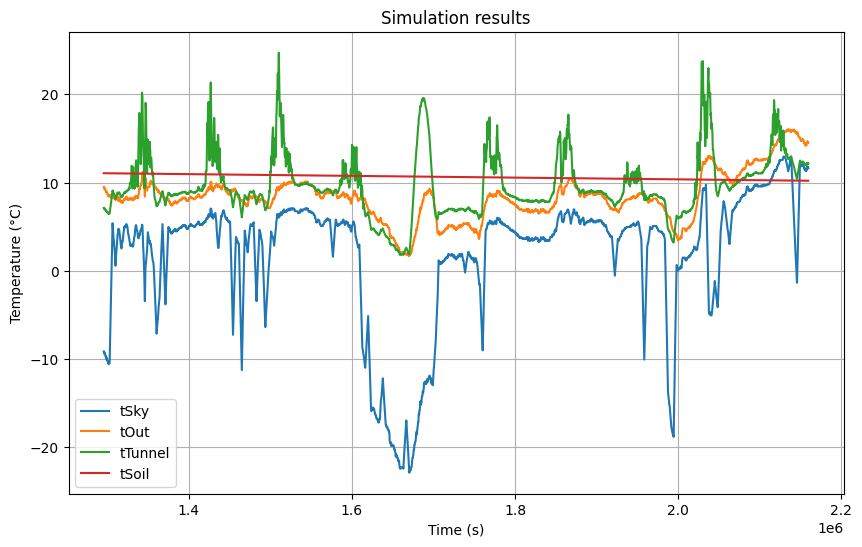

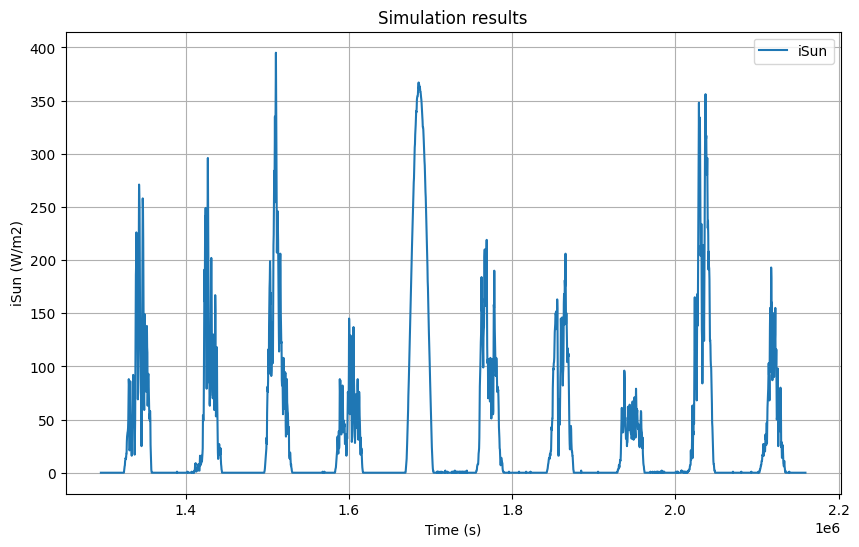

In [127]:
"""Make graphs"""
variable_names = output_2.columns.get_level_values(0)
descriptions = output_2.columns.get_level_values(1)
units = output_2.columns.get_level_values(2)

# Create dictionaries for descriptions and units
descriptions_dict = dict(zip(variable_names, descriptions))
units_dict = dict(zip(variable_names, units))

"""Present results in a graph graphs"""
# Choose variables out of output_df.columns
# For a description of a variable var, see descriptions_dict[var]. For the unit, see units_dict[var]
chosen_vars = ["tSky", "tOut", "tTunnel", "tSoil"]

plt.figure(figsize=(10, 6))

for var in chosen_vars:
    plt.plot(output_2["Time"], output_2[var], label=var)

plt.xlabel("Time (s)")
plt.ylabel("Temperature (°C)")
plt.title("Simulation results")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))

plt.plot(output_2["Time"], output_2["iSun"], label="iSun")

plt.xlabel("Time (s)")
plt.ylabel("iSun (W/m2)")
plt.title("Simulation results")
plt.legend()
plt.grid(True)
plt.show()

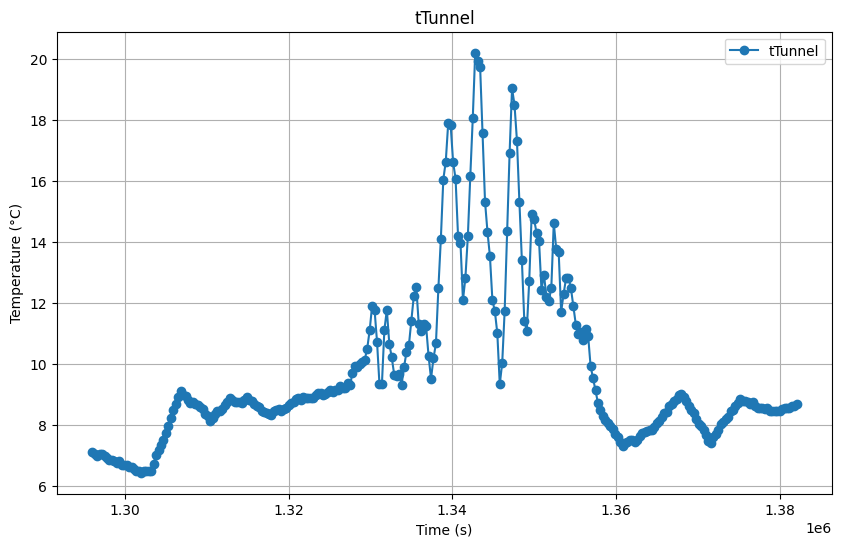

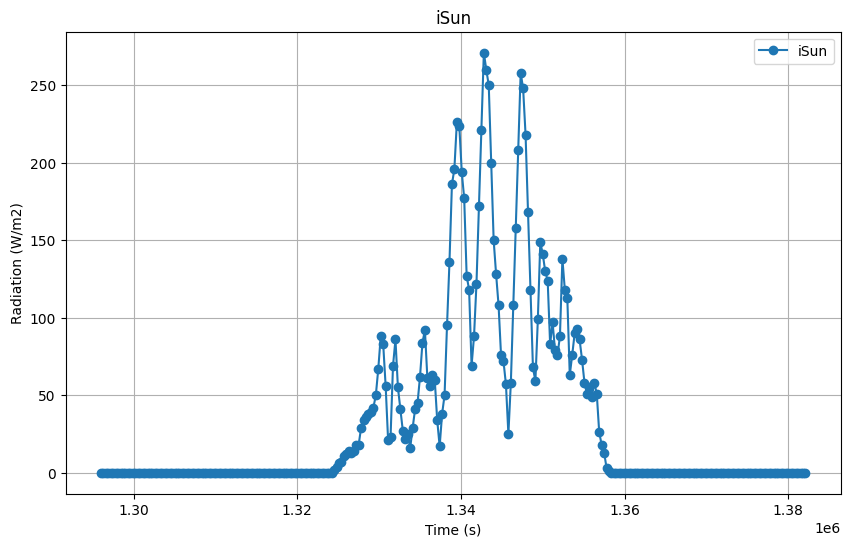

In [90]:
""" Zoom in """
zoomed_output = output_2
zoomed_output.columns = variable_names
zoomed_output = zoomed_output[zoomed_output["Time"] < 16 * 24 * 60 * 60]

chosen_vars = ["tTunnel"]

plt.figure(figsize=(10, 6))

for var in chosen_vars:
    plt.plot(zoomed_output["Time"], zoomed_output[var], '-o', label=var)

plt.xlabel("Time (s)")
plt.ylabel("Temperature (°C)")
plt.title("tTunnel")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))

plt.plot(zoomed_output["Time"], zoomed_output["iSun"], '-o', label="iSun")

plt.xlabel("Time (s)")
plt.ylabel("Radiation (W/m2)")
plt.title("iSun")
plt.legend()
plt.grid(True)
plt.show()



In [128]:
# A guess at capacity:
# The air has a capacity of 1200 J/m3/K (Stanghellini textbook)
# Soil has a capacity of 1.73e6 J/m3/K (Vanthoor)
# Per m2 assume we consider 2.5 m of air and 0.1 m of soil, that gives:
# 1200x(2.5/2.6) + 1.73e6 (0.1/2.6) = 1153 + 66538 = 67691


dynamic_model = tunnel_model
dynamic_model["tTunnel"] = {
        "description": "Temperature of the unventilated greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9 (rearranged to isolate tTunnel)",
        "type": "state",
        "init": "8",
        "definition": "1/(67691)*(" \
        "tau * iSun " \
        "- fTunnelSky * epsCover * alphaR * (tTunnel - tSky) " \
        "- aCoverOverSoil * alphaCover * (tTunnel - tOut) " \
        "- fTunnelSoil * epsSoil * alphaR * (tTunnel - tSoil) " \
        "- alphaSoil * (tTunnel - tSoil)"
    ")"
    }

mdl_3 = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=[tunnel_model, os.path.join("input", "example_weather.csv"), options], 
    output_path=os.path.join("output", "output_3.csv")
)
mdl_3.run()



Loading model from input\example_weather.csv
Simulation started at time (ISO format): 2026-07-30T13:50:21.640681
Running: 100.00%

Simulation complete at time (ISO format): 2026-07-30T13:50:23.539816
Simulated 9.996527777777779 days
Elapsed time: 1.899134635925293 seconds
Output saved to file output\output_3.csv
Model structure log saved to output\output_3_model_struct_log.json
Simulation log saved to output\output_3_simulation_log.txt


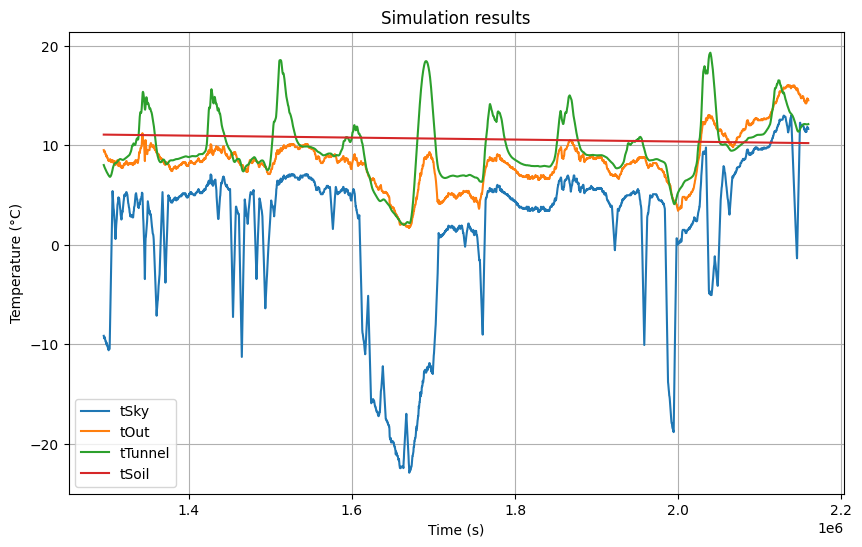

In [131]:
"""Load simulation result"""
output_3 = pd.read_csv(os.path.join("output", "output_3.csv"), header=[0,1,2], low_memory=False)

"""Make graphs"""
variable_names = output_3.columns.get_level_values(0)
descriptions = output_3.columns.get_level_values(1)
units = output_3.columns.get_level_values(2)

# Create dictionaries for descriptions and units
descriptions_dict = dict(zip(variable_names, descriptions))
units_dict = dict(zip(variable_names, units))

"""Present results in a graph graphs"""
# Choose variables out of output_df.columns
# For a description of a variable var, see descriptions_dict[var]. For the unit, see units_dict[var]
chosen_vars = ["tSky", "tOut", "tTunnel", "tSoil"]

plt.figure(figsize=(10, 6))

for var in chosen_vars:
    plt.plot(output_3["Time"], output_3[var], label=var)

plt.xlabel("Time (s)")
plt.ylabel("Temperature (°C)")
plt.title("Simulation results")
plt.legend()
plt.grid(True)
plt.show()

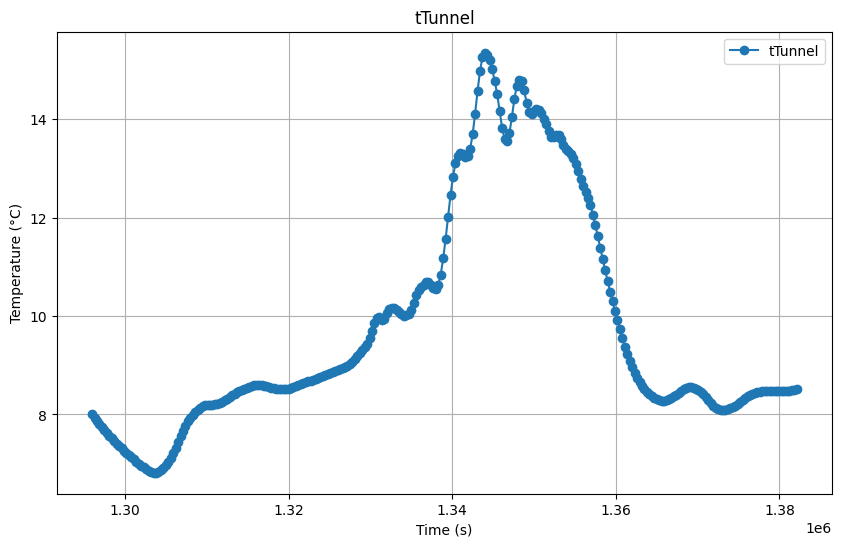

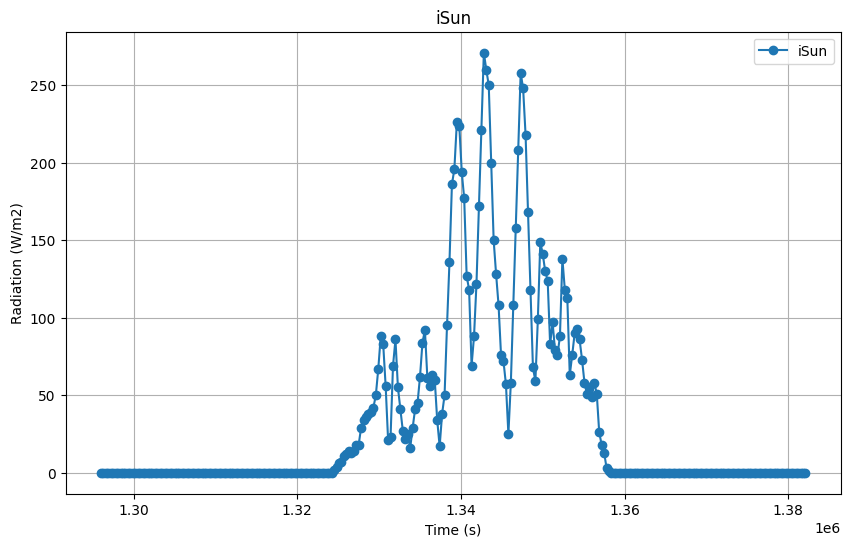

In [130]:
""" Zoom in """
zoomed_output = output_3
zoomed_output.columns = variable_names
zoomed_output = zoomed_output[zoomed_output["Time"] < 16 * 24 * 60 * 60]

chosen_vars = ["tTunnel"]

plt.figure(figsize=(10, 6))

for var in chosen_vars:
    plt.plot(zoomed_output["Time"], zoomed_output[var], '-o', label=var)

plt.xlabel("Time (s)")
plt.ylabel("Temperature (°C)")
plt.title("tTunnel")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 6))

plt.plot(zoomed_output["Time"], zoomed_output["iSun"], '-o', label="iSun")

plt.xlabel("Time (s)")
plt.ylabel("Radiation (W/m2)")
plt.title("iSun")
plt.legend()
plt.grid(True)
plt.show()

